#### [PREV](8.OOP_Neural_Network_Adv.ipynb) | [HOME](../README.md) | [NEXT](10.OOP_K_Means_Clustering.ipynb)

---

# OOP Decision Trees Implementation

In this notebook you will visualise how a decision tree is split using information gain. This is a complex implementation. Students are not expected to write their own implementation, but rather step through the Jupyter Notebook and deepen their understanding of 'information gain' and 'splitting' through the visual demonstration.

#### Step 1: Import Dependencies

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree # Import Decision Tree Classifier and a function to draw the tree
from sklearn import metrics # Import scikit-learn metrics module for accuracy calculation

#### Step 2: Preview The Data

|                                                     |   Ear Shape | Face Shape | Whiskers |   Cat  |
|:---------------------------------------------------:|:---------:|:-----------:|:---------:|:------:|
| <img src="images/0.png" alt="drawing" width="50"/> |   Pointy   |   Round     |  Present  |    1   |
| <img src="images/1.png" alt="drawing" width="50"/> |   Floppy   |  Not Round  |  Present  |    1   |
| <img src="images/2.png" alt="drawing" width="50"/> |   Floppy   |  Round      |  Absent   |    0   |
| <img src="images/3.png" alt="drawing" width="50"/> |   Pointy   |  Not Round  |  Present  |    0   |
| <img src="images/4.png" alt="drawing" width="50"/> |   Pointy   |   Round     |  Present  |    1   |
| <img src="images/5.png" alt="drawing" width="50"/> |   Pointy   |   Round     |  Absent   |    1   |
| <img src="images/6.png" alt="drawing" width="50"/> |   Floppy   |  Not Round  |  Absent   |    0   |
| <img src="images/7.png" alt="drawing" width="50"/> |   Pointy   |  Round      |  Absent   |    1   |
| <img src="images/8.png" alt="drawing" width="50"/> |    Floppy  |   Round     |  Absent   |    0   |
| <img src="images/9.png" alt="drawing" width="50"/> |   Floppy   |  Round      |  Absent   |    0   |


We will use **binary encoding** to encode the categorical features, so each feature becomes 1 or 0. They will be as follows:

- Ear Shape: Pointy = 1, Floppy = 0
- Face Shape: Round = 1, Not Round = 0
- Whiskers: Present = 1, Absent = 0

Therefore, we have two sets:

- `X_train`: for each example, contains 3 features:
            - Ear Shape (1 if pointy, 0 otherwise)
            - Face Shape (1 if round, 0 otherwise)
            - Whiskers (1 if present, 0 otherwise)
            
- `y_train`: whether the animal is a cat
            - 1 if the animal is a cat
            - 0 otherwise

#### Step 3: Import The Data

In [2]:
# Feature variable
X_train = np.array([[1, 1, 1],
[0, 0, 1],
[0, 1, 0],
[1, 0, 1],
[1, 1, 1],
[1, 1, 0],
[0, 0, 0],
[1, 1, 0],
[0, 1, 0],
[0, 1, 0]])

# Target or ground truth variable
y_train = np.array([1, 1, 0, 0, 1, 1, 0, 1, 0, 0])

# Column names variable
feature_cols = ['Ear shape', 'Face shape', 'Whiskers']


In [3]:
# For instance, the first example
print(X_train[0])
print(y_train[0])

[1 1 1]
1


This means that the first example has a pointy ear shape, a round face shape and whiskers, and it is a cat.

#### Step 4: Instantiate a Decision Tree Classifier Object

In [4]:
# criterion='entropy' makes the tree choose each split using information gain
# random_state makes the result the same every time the notebook is run
clf = DecisionTreeClassifier(criterion='entropy', random_state=42)

#### Step 5: Fit The Model

In [5]:
clf = clf.fit(X_train, y_train)

#### Step 6: Predict Values

In [6]:
# Predict the response for dataset
y_pred = clf.predict(X_train)

print(y_pred)

[1 1 0 0 1 1 0 1 0 0]


#### Step 7: Evaluate The Model

In [7]:
# Model Accuracy, how often is the classifier correct?
print("Accuracy:", metrics.accuracy_score(y_train, y_pred))

Accuracy: 1.0


> [!Note]
> The model is being tested on the same data it was trained on, so an accuracy of 1.0 is expected. With only 10 examples there is not enough data to hold some back for a separate test set.

#### Step 8: Visualise The Model & Statistics

At each node, we compute the information gain for each feature, then split the node on the feature with the highest information gain. Information gain compares the entropy of the node with the weighted entropy of the two nodes created by the split.

For this dataset, the best feature for the first split is Ear Shape. Run the code below to see the tree scikit-learn built. Each box shows the split condition, the entropy, the number of samples and the predicted class. In scikit-learn's diagram the left branch is where the condition is True, so `Ear shape <= 0.5` sends floppy ears to the left.

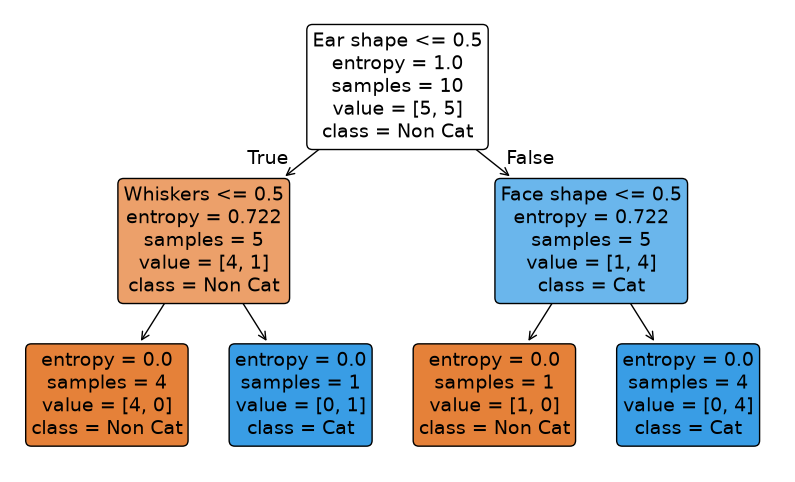

In [8]:
plt.figure(figsize=(10, 6))
plot_tree(clf,
          feature_names=feature_cols,
          class_names=['Non Cat', 'Cat'],
          filled=True,
          rounded=True)
plt.show()

The custom visualisation below shows which animals end up in each node after each split. In this diagram the left branch is where the feature equals 1 (for example, pointy ears):

> [!Note]
> This diagram needs the Graphviz program. It is installed in the Codespace. If you see `"dot" not found in path` when running locally, install [Graphviz](https://graphviz.org/download/) and restart VSCode.

 Depth 0, Root: Split on feature: 0
- Depth 1, Left: Split on feature: 1
  -- Left leaf node with indices [0, 4, 5, 7]
  -- Right leaf node with indices [3]
- Depth 1, Right: Split on feature: 2
  -- Left leaf node with indices [1]
  -- Right leaf node with indices [2, 6, 8, 9]


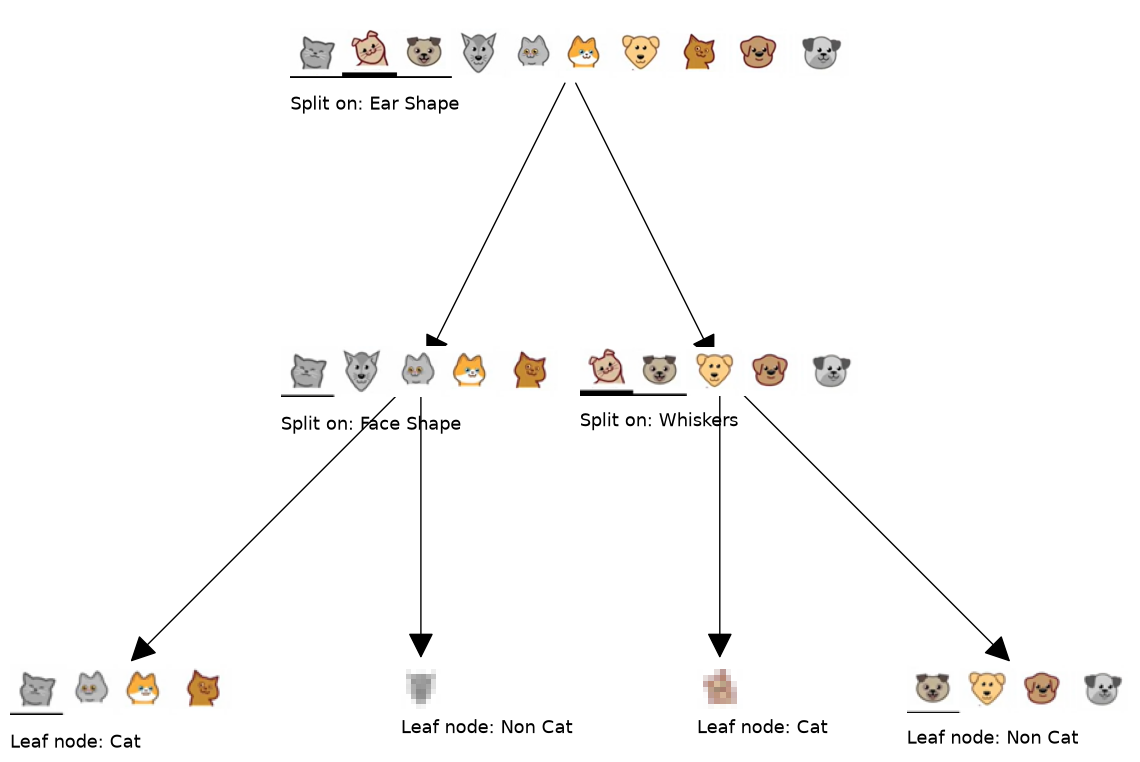

In [9]:
# Note:
#  - This is a custom module, built to visualise this problem
#  - Students should scroll past the code to see the visualisation
import sys
sys.path.insert(1, 'lib')
from utils import *

tree = []
build_tree_recursive(X_train, y_train, [0,1,2,3,4,5,6,7,8,9], "Root", max_depth=2, current_depth=0, tree = tree)
generate_tree_viz([0,1,2,3,4,5,6,7,8,9], y_train, tree)